# K-Means Clustering

Estimated time needed: **25-30** minutes

## Objectives

After completing this lab you will be able to:

*   Use scikit-learn's K-Means Clustering to cluster data


## Introduction

There are many models for **clustering** out there. In this notebook, we will be presenting the model that is considered one of the simplest models amongst them. Despite its simplicity, the **K-means** is vastly used for clustering in many data science applications, it is especially useful if you need to quickly discover insights from **unlabeled data**. In this notebook, you will learn how to use k-Means for customer segmentation.

Some real-world applications of k-means:

*   Customer segmentation
*   Understand what the visitors of a website are trying to accomplish
*   Pattern recognition
*   Machine learning
*   Data compression

In this notebook we practice k-means clustering with 2 examples:

*   k-means on a random generated dataset
*   Using k-means for customer segmentation


<h1>Table of contents</h1>

<div class="alert alert-block alert-info" style="margin-top: 20px">
    <ul>
        <li><a href="https://#random_generated_dataset">k-Means on a randomly generated dataset</a></li>
            <ol>
                <li><a href="https://#setting_up_K_means">Setting up K-Means</a></li>
                <li><a href="https://#creating_visual_plot">Creating the Visual Plot</a></li>
            </ol>
        <p></p>
        <li><a href="https://#customer_segmentation_K_means">Customer Segmentation with K-Means</a></li>
            <ol>
                <li><a href="https://#pre_processing">Pre-processing</a></li>
                <li><a href="https://#modeling">Modeling</a></li>
                <li><a href="https://#insights">Insights</a></li>
            </ol>
    </ul>
</div>
<br>
<hr>


### Import the Libraries

Let's first import the required libraries.
Also run <b> %matplotlib inline </b> since we will be plotting in this section.


In [45]:
#you are running the lab in your  browser, so we will install the libraries using ``piplite``
# For local Python
%matplotlib inline

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer



In [44]:
import random 
import numpy as np 
import matplotlib.pyplot as plt 
from sklearn.cluster import KMeans 
from sklearn.datasets import make_blobs 
%matplotlib inline

### Download the Data


In [41]:
import pandas as pd

url = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%204/data/Cust_Segmentation.csv"
filename = "Cust_Segmentation.csv"

# Directly load the dataset from URL
df = pd.read_csv(url)
df.head()


,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2


<h1 id="random_generated_dataset">k-Means on a randomly generated dataset</h1>

Let's create our own dataset for this lab!


First we need to set a random seed. Use <b>numpy's random.seed()</b> function, where the seed will be set to <b>0</b>.


In [39]:
np.random.seed(0)

Next we will be making <i> random clusters </i> of points by using the <b> make_blobs </b> class. The <b> make_blobs </b> class can take in many inputs, but we will be using these specific ones. <br> <br> <b> <u> Input </u> </b>

<ul>
    <li> <b>n_samples</b>: The total number of points equally divided among clusters. </li>
    <ul> <li> Value will be: 5000 </li> </ul>
    <li> <b>centers</b>: The number of centers to generate, or the fixed center locations. </li>
    <ul> <li> Value will be: [[4, 4], [-2, -1], [2, -3],[1,1]] </li> </ul>
    <li> <b>cluster_std</b>: The standard deviation of the clusters. </li>
    <ul> <li> Value will be: 0.9 </li> </ul>
</ul>
<br>
<b> <u> Output </u> </b>
<ul>
    <li> <b>X</b>: Array of shape [n_samples, n_features]. (Feature Matrix)</li>
    <ul> <li> The generated samples. </li> </ul> 
    <li> <b>y</b>: Array of shape [n_samples]. (Response Vector)</li>
    <ul> <li> The integer labels for cluster membership of each sample. </li> </ul>
</ul>


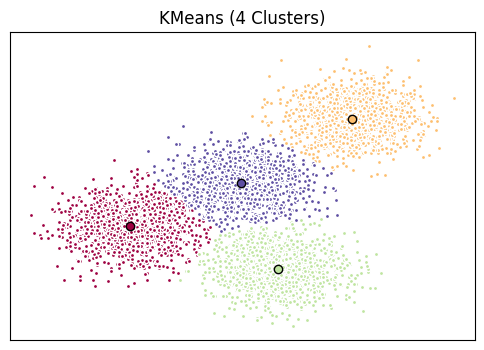

In [38]:
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np

# Generate synthetic data
X, y = make_blobs(
    n_samples=5000,
    centers=[[4,4], [-2, -1], [2, -3], [1, 1]],
    cluster_std=0.9,
    random_state=42
)

# Fit KMeans with 4 clusters
k_means = KMeans(init="k-means++", n_clusters=4, n_init=12, random_state=42)
k_means.fit(X)

# Extract labels and centers
k_means_labels = k_means.labels_
k_means_cluster_centers = k_means.cluster_centers_

# Plot results
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(k_means_labels))))

for k, col in zip(range(4), colors):
    m = (k_means_labels == k)
    ax.plot(X[m, 0], X[m, 1], 'w', markerfacecolor=col, marker='.')
    c = k_means_cluster_centers[k]
    ax.plot(c[0], c[1], 'o', markerfacecolor=col, markeredgecolor='k', markersize=6)

ax.set_title('KMeans (4 Clusters)')
ax.set_xticks(())
ax.set_yticks(())
plt.show()


Display the scatter plot of the randomly generated data.


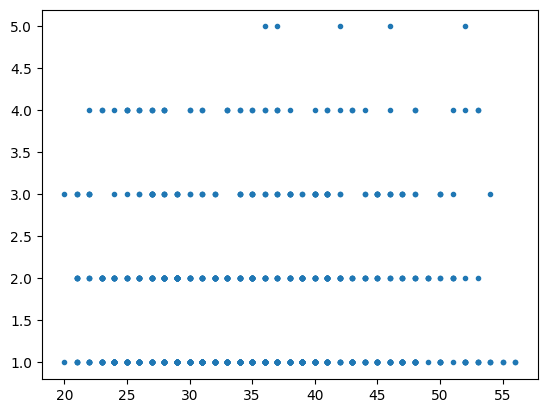

In [36]:
plt.scatter(X[:, 0], X[:, 1], marker='.')

<h2 id="setting_up_K_means">Setting up K-Means</h2>
Now that we have our random data, let's set up our K-Means Clustering.


The KMeans class has many parameters that can be used, but we will be using these three:

<ul>
    <li> <b>init</b>: Initialization method of the centroids. </li>
    <ul>
        <li> Value will be: "k-means++" </li>
        <li> k-means++: Selects initial cluster centers for k-mean clustering in a smart way to speed up convergence.</li>
    </ul>
    <li> <b>n_clusters</b>: The number of clusters to form as well as the number of centroids to generate. </li>
    <ul> <li> Value will be: 4 (since we have 4 centers)</li> </ul>
    <li> <b>n_init</b>: Number of time the k-means algorithm will be run with different centroid seeds. The final results will be the best output of n_init consecutive runs in terms of inertia. </li>
    <ul> <li> Value will be: 12 </li> </ul>
</ul>

Initialize KMeans with these parameters, where the output parameter is called <b>k_means</b>.


In [35]:
k_means = KMeans(init = "k-means++", n_clusters = 4, n_init = 12)

Now let's fit the KMeans model with the feature matrix we created above, <b> X </b>.


In [31]:
k_means = KMeans(init = "k-means++", n_clusters = 4, n_init = 12)

Now let's grab the labels for each point in the model using KMeans' <b> .labels\_ </b> attribute and save it as <b> k_means_labels </b>.


In [28]:
k_means_labels = k_means.labels_
k_means_labels

array([3, 0, 0, 2, 0, 3, 3, 3, 2, 3, 3, 2, 2, 3, 1, 2, 2, 2, 3, 3, 2, 3,
       1, 3, 0, 3, 2, 3, 3, 3, 3, 3, 1, 2, 3, 2, 1, 1, 2, 3, 1, 0, 2, 0,
       3, 3, 2, 2, 2, 2, 3, 3, 1, 3, 0, 1, 1, 2, 3, 3, 3, 3, 3, 3, 2, 2,
       3, 1, 2, 1, 2, 3, 3, 2, 2, 2, 3, 2, 0, 3, 3, 0, 0, 2, 3, 2, 2, 2,
       1, 1, 3, 2, 1, 1, 2, 3, 2, 3, 1, 2, 1, 0, 3, 1, 1, 0, 3, 2, 3, 3,
       3, 2, 2, 1, 2, 3, 2, 3, 0, 2, 2, 2, 2, 3, 3, 3, 2, 2, 2, 2, 3, 3,
       2, 2, 2, 2, 3, 2, 3, 1, 1, 2, 2, 2, 0, 2, 3, 1, 2, 2, 3, 3, 1, 3,
       3, 3, 3, 3, 1, 1, 2, 3, 3, 3, 2, 2, 2, 2, 2, 3, 0, 2, 2, 1, 3, 1,
       3, 2, 1, 3, 1, 3, 2, 0, 1, 0, 3, 3, 3, 3, 2, 3, 3, 1, 3, 2, 2, 3,
       0, 2, 3, 2, 1, 3, 3, 3, 2, 3, 3, 1, 2, 3, 3, 3, 2, 1, 1, 0, 3, 3,
       1, 3, 2, 2, 2, 2, 0, 2, 2, 3, 3, 3, 3, 2, 0, 2, 3, 1, 0, 2, 2, 3,
       2, 2, 2, 3, 3, 3, 2, 2, 2, 2, 3, 2, 3, 1, 3, 1, 2, 2, 2, 0, 3, 1,
       3, 3, 2, 3, 2, 3, 1, 2, 3, 3, 2, 1, 1, 1, 2, 2, 2, 0, 3, 2, 3, 2,
       3, 2, 3, 3, 2, 3, 2, 1, 2, 2, 1, 2, 1, 3, 3,

We will also get the coordinates of the cluster centers using KMeans' <b> .cluster_centers\_ </b> and save it as <b> k_means_cluster_centers </b>.


In [22]:
k_means_cluster_centers = k_means.cluster_centers_
k_means_cluster_centers

array([[ 0.76864483, -0.1594805 ,  0.73966138,  0.33007302, -0.08268928,
        -0.00413552, -0.40833523, -0.28915496, -1.21733242],
       [-0.59992641,  0.00625332, -0.62752021, -0.48536139, -0.30961581,
        -0.36191137,  0.17643888, -0.02136789,  0.41473786],
       [ 0.74449046,  0.55785018,  1.0189812 ,  1.6919048 ,  2.17430965,
         2.19607331,  0.46169602,  1.20850418,  2.04680814]])

<h2 id="creating_visual_plot">Creating the Visual Plot</h2>

So now that we have the random data generated and the KMeans model initialized, let's plot them and see what it looks like!


Please read through the code and comments to understand how to plot the model.


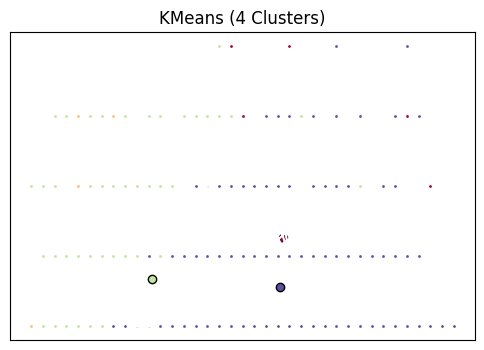

In [27]:
from sklearn.cluster import KMeans
import numpy as np
import matplotlib.pyplot as plt

# Fit on your normalized data
k_means = KMeans(init="k-means++", n_clusters=4, n_init=12, random_state=42).fit(Clus_dataSet)

# Now these exist
k_means_labels = k_means.labels_
k_means_cluster_centers = k_means.cluster_centers_

# Plot
fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(k_means_labels))))

for k, col in zip(range(len(set(k_means_labels))), colors):
    m = (k_means_labels == k)
    ax.plot(Clus_dataSet[m, 0], Clus_dataSet[m, 1], 'w', markerfacecolor=col, marker='.')
    c = k_means_cluster_centers[k]
    ax.plot(c[0], c[1], 'o', markerfacecolor=col, markeredgecolor='k', markersize=6)

ax.set_title('KMeans (4 Clusters)')
ax.set_xticks(())
ax.set_yticks(())
plt.show()


## Practice

Try to cluster the above dataset into 3 clusters.\
Notice: do not generate the data again, use the same dataset as above.


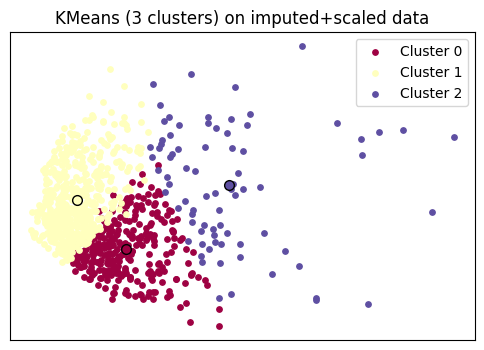

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA

# 1) Load
path = r"C:\Users\gulme\Desktop\aifirstclass\lab-k-means-clustering\Cust_Segmentation.csv"
df = pd.read_csv(path)

# 2) Numeric features only
X = df.select_dtypes(include=["number"]).values

# 3) Impute -> Scale -> KMeans(3)
imp = SimpleImputer(strategy="mean")
scaler = StandardScaler()
X_imp = imp.fit_transform(X)
X_scaled = scaler.fit_transform(X_imp)

k3 = KMeans(n_clusters=3, n_init="auto", random_state=42)
labels = k3.fit_predict(X_scaled)

# 4) 2D visualization with PCA (points + cluster centers)
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_scaled)
centers_2d = pca.transform(k3.cluster_centers_)

fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
colors = plt.cm.Spectral(np.linspace(0, 1, 3))

for k, col in zip(range(3), colors):
    m = labels == k
    ax.scatter(Z[m, 0], Z[m, 1], c=[col], s=15, label=f"Cluster {k}")
    ax.plot(centers_2d[k, 0], centers_2d[k, 1], 'o', markerfacecolor=col,
            markeredgecolor='k', markersize=7)

ax.set_title("KMeans (3 clusters) on imputed+scaled data")
ax.set_xticks(())
ax.set_yticks(())
ax.legend()
plt.show()

# Optional: attach labels back to df
df["Cluster"] = labels


<details><summary>Click here for the solution</summary>

```python
k_means3 = KMeans(init = "k-means++", n_clusters = 3, n_init = 12)
k_means3.fit(X)
fig = plt.figure(figsize=(6, 4))
colors = plt.cm.Spectral(np.linspace(0, 1, len(set(k_means3.labels_))))
ax = fig.add_subplot(1, 1, 1)
for k, col in zip(range(len(k_means3.cluster_centers_)), colors):
    my_members = (k_means3.labels_ == k)
    cluster_center = k_means3.cluster_centers_[k]
    ax.plot(X[my_members, 0], X[my_members, 1], 'w', markerfacecolor=col, marker='.')
    ax.plot(cluster_center[0], cluster_center[1], 'o', markerfacecolor=col,  markeredgecolor='k', markersize=6)
plt.show()

```

</details>


<h1 id="customer_segmentation_K_means">Customer Segmentation with K-Means</h1>

Imagine that you have a customer dataset, and you need to apply customer segmentation on this historical data.
Customer segmentation is the practice of partitioning a customer base into groups of individuals that have similar characteristics. It is a significant strategy as a business can target these specific groups of customers and effectively allocate marketing resources. For example, one group might contain customers who are high-profit and low-risk, that is, more likely to purchase products, or subscribe for a service. A business task is to retain those customers. Another group might include customers from non-profit organizations and so on.

Let's download the datasetfrom IBM Object Storage.  **Did you know?** When it comes to Machine Learning, you will likely be working with large datasets. As a business, where can you host your data? IBM is offering a unique opportunity for businesses, with 10 Tb of IBM Cloud Object Storage: [Sign up now for free](http://cocl.us/ML0101EN-IBM-Offer-CC)


In [ ]:
path='https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%204/data/Cust_Segmentation.csv'

### Load Data From CSV File

Before you can work with the data, you must use the URL to get the Cust_Segmentation.csv.


   Customer Id  Age  Edu  Years Employed  Income  Card Debt  Other Debt  \
0            1   41    2               6      19      0.124       1.073   
1            2   47    1              26     100      4.582       8.218   
2            3   33    2              10      57      6.111       5.802   
3            4   29    2               4      19      0.681       0.516   
4            5   47    1              31     253      9.308       8.908   

   Defaulted Address  DebtIncomeRatio  
0        0.0  NBA001              6.3  
1        0.0  NBA021             12.8  
2        1.0  NBA013             20.9  
3        0.0  NBA009              6.3  
4        0.0  NBA008              7.2  


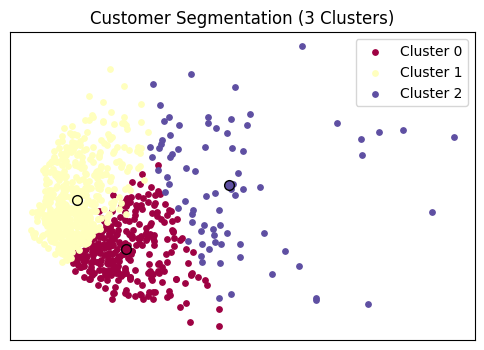

   Customer Id  Age  Edu  Years Employed  Income  Card Debt  Other Debt  \
0            1   41    2               6      19      0.124       1.073   
1            2   47    1              26     100      4.582       8.218   
2            3   33    2              10      57      6.111       5.802   
3            4   29    2               4      19      0.681       0.516   
4            5   47    1              31     253      9.308       8.908   

   Defaulted Address  DebtIncomeRatio  Cluster  
0        0.0  NBA001              6.3        0  
1        0.0  NBA021             12.8        2  
2        1.0  NBA013             20.9        2  
3        0.0  NBA009              6.3        1  
4        0.0  NBA008              7.2        2  


In [6]:
#await download(path, "Cust_Segmentation.csv")
#filename ="Cust_Segmentation.csv"

# Import libraries
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import numpy as np

# 1. Download and load dataset
path = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-ML0101EN-SkillsNetwork/labs/Module%204/data/Cust_Segmentation.csv"
df = pd.read_csv(path)
print(df.head())

# 2. Keep numeric columns only
X = df.select_dtypes(include=["number"]).values

# 3. Handle NaN, scale, then cluster
imp = SimpleImputer(strategy="mean")
scaler = StandardScaler()
X_imp = imp.fit_transform(X)
X_scaled = scaler.fit_transform(X_imp)

k3 = KMeans(n_clusters=3, n_init="auto", random_state=42)
labels = k3.fit_predict(X_scaled)

# 4. Optional visualization (2D PCA projection)
pca = PCA(n_components=2, random_state=42)
Z = pca.fit_transform(X_scaled)
centers_2d = pca.transform(k3.cluster_centers_)

fig = plt.figure(figsize=(6, 4))
ax = fig.add_subplot(1, 1, 1)
colors = plt.cm.Spectral(np.linspace(0, 1, 3))
for k, col in zip(range(3), colors):
    m = labels == k
    ax.scatter(Z[m, 0], Z[m, 1], c=[col], s=15, label=f"Cluster {k}")
    ax.plot(centers_2d[k, 0], centers_2d[k, 1], 'o',
            markerfacecolor=col, markeredgecolor='k', markersize=7)

ax.set_title("Customer Segmentation (3 Clusters)")
ax.legend()
ax.set_xticks(())
ax.set_yticks(())
plt.show()

# 5. Attach labels
df["Cluster"] = labels
print(df.head())


we create a pandas dataframe


In [7]:
import pandas as pd
cust_df = pd.read_csv("Cust_Segmentation.csv")
cust_df.head()

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,Address,DebtIncomeRatio
0,1,41,2,6,19,0.124,1.073,0.0,NBA001,6.3
1,2,47,1,26,100,4.582,8.218,0.0,NBA021,12.8
2,3,33,2,10,57,6.111,5.802,1.0,NBA013,20.9
3,4,29,2,4,19,0.681,0.516,0.0,NBA009,6.3
4,5,47,1,31,253,9.308,8.908,0.0,NBA008,7.2


<h2 id="pre_processing">Pre-processing</h2


As you can see, **Address** in this dataset is a categorical variable. The k-means algorithm isn't directly applicable to categorical variables because the Euclidean distance function isn't really meaningful for discrete variables. So, let's drop this feature and run clustering.


In [8]:
df = cust_df.drop('Address', axis=1)
df.head()

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Convert to numpy
X = df.values

# Handle missing values
imp = SimpleImputer(strategy="mean")
X_imp = imp.fit_transform(X)

# Standardize
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imp)

# Fit KMeans
kmeans = KMeans(n_clusters=3, n_init="auto", random_state=42)
labels = kmeans.fit_predict(X_scaled)

# Add labels back to DataFrame
df["Cluster"] = labels
df.head()


,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Cluster
0,1,41,2,6,19,0.124,1.073,0.0,6.3,0
1,2,47,1,26,100,4.582,8.218,0.0,12.8,2
2,3,33,2,10,57,6.111,5.802,1.0,20.9,2
3,4,29,2,4,19,0.681,0.516,0.0,6.3,1
4,5,47,1,31,253,9.308,8.908,0.0,7.2,2


#### Normalizing over the standard deviation

Now let's normalize the dataset. But why do we need normalization in the first place? Normalization is a statistical method that helps mathematical-based algorithms to interpret features with different magnitudes and distributions equally. We use **StandardScaler()** to normalize our dataset.


In [9]:
import numpy as np
from sklearn.preprocessing import StandardScaler

# Exclude Customer Id (first column)
X = df.values[:, 1:]

# Replace NaN or inf with numerical values (0)
X = np.nan_to_num(X)

# Normalize (mean = 0, std = 1)
Clus_dataSet = StandardScaler().fit_transform(X)

Clus_dataSet


array([[ 0.74291541,  0.31212243, -0.37878978, ..., -0.52379654,
        -0.57652509, -1.21733242],
       [ 1.48949049, -0.76634938,  2.5737211 , ..., -0.52379654,
         0.39138677,  2.04680814],
       [-0.25251804,  0.31212243,  0.2117124 , ...,  1.90913822,
         1.59755385,  2.04680814],
       ...,
       [-1.24795149,  2.46906604, -1.26454304, ...,  1.90913822,
         3.45892281,  0.41473786],
       [-0.37694723, -0.76634938,  0.50696349, ..., -0.52379654,
        -1.08281745,  0.41473786],
       [ 2.1116364 , -0.76634938,  1.09746566, ..., -0.52379654,
        -0.2340332 , -1.21733242]], shape=(850, 9))

<h2 id="modeling">Modeling</h2>


In our example (if we didn't have access to the k-means algorithm), it would be the same as guessing that each customer group would have certain age, income, education, etc, with multiple tests and experiments. However, using the K-means clustering we can do all this process much easier.

Let's apply k-means on our dataset, and take a look at cluster labels.


In [10]:
from sklearn.cluster import KMeans

clusterNum = 3
k_means = KMeans(init="k-means++", n_clusters=clusterNum, n_init=12, random_state=42)
k_means.fit(Clus_dataSet)

labels = k_means.labels_
print(labels)


[0 2 2 1 2 0 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 1 0 2 0 1 0 0 0 0 0 1 1 0 1 1
 1 1 0 1 2 1 2 0 0 1 1 1 1 0 0 1 0 2 1 1 1 0 0 0 0 0 0 1 1 0 1 1 1 1 0 0 1
 1 1 0 1 2 0 0 2 2 1 0 1 1 1 1 1 0 1 1 1 1 0 1 0 1 1 1 2 0 0 1 2 0 1 0 0 0
 1 1 1 1 0 1 0 2 1 1 1 1 0 0 0 1 1 1 1 0 0 1 1 1 1 0 1 0 1 1 1 1 1 2 1 0 1
 1 1 0 0 1 0 0 0 0 0 1 1 1 0 0 0 1 1 1 1 1 0 2 1 1 1 0 1 0 1 1 0 1 0 1 2 1
 2 0 0 0 0 1 0 0 1 0 1 1 0 2 1 0 1 1 0 0 0 1 0 0 1 1 0 0 0 1 1 0 2 0 0 1 0
 1 1 1 1 2 1 1 0 0 0 0 1 2 1 0 1 2 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 0 1 0 1 1
 1 1 2 0 1 0 0 1 0 1 0 1 1 0 0 1 1 1 1 1 1 1 2 0 1 0 1 0 1 0 0 1 0 1 2 1 1
 1 1 1 0 0 0 1 1 1 0 0 1 1 0 1 1 1 1 0 1 1 1 0 1 2 1 2 1 1 0 1 1 0 0 0 2 1
 0 0 0 1 0 1 0 0 0 0 1 2 0 1 1 1 1 2 1 0 1 1 0 2 1 1 1 0 1 1 1 0 1 0 0 0 0
 1 1 0 0 1 1 1 0 1 1 1 1 1 0 2 0 0 1 1 1 1 2 0 2 1 1 1 0 1 1 1 1 1 1 1 2 1
 0 1 0 1 0 1 1 1 0 0 1 0 1 0 2 1 1 2 0 0 0 1 1 0 0 1 1 2 1 1 1 2 0 0 0 1 2
 0 1 0 0 0 0 2 1 1 1 2 1 1 1 1 0 0 2 1 1 1 1 0 1 0 2 0 1 0 0 0 1 0 1 1 1 1
 1 0 1 1 1 0 2 1 1 1 2 0 

<h2 id="insights">Insights</h2>

We assign the labels to each row in the dataframe.


In [19]:
df["Clus_km"] = labels
df.head(5)

,Customer Id,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Cluster,Clus_km
0,1,41,2,6,19,0.124,1.073,0.0,6.3,0,0
1,2,47,1,26,100,4.582,8.218,0.0,12.8,2,1
2,3,33,2,10,57,6.111,5.802,1.0,20.9,2,1
3,4,29,2,4,19,0.681,0.516,0.0,6.3,1,2
4,5,47,1,31,253,9.308,8.908,0.0,7.2,2,1


We can easily check the centroid values by averaging the features in each cluster.


In [16]:
# Diagnostics
print(df.columns.tolist())
print(len(df), len(labels))  # must match

# If missing, reattach labels
df["Clus_km"] = labels  # ensure labels came from the same rows as df

# Group means (numeric only)
centroids = df.groupby("Clus_km").mean(numeric_only=True)
print(centroids)


['Customer Id', 'Age', 'Edu', 'Years Employed', 'Income', 'Card Debt', 'Other Debt', 'Defaulted', 'DebtIncomeRatio', 'Cluster']
850 850
         Customer Id        Age       Edu  Years Employed      Income  \
Clus_km                                                                 
0         395.267797  41.206780  1.562712       13.576271   59.389831   
1         444.861345  30.207983  1.716387        4.315126   27.978992   
2         421.734177  41.012658  2.227848       15.468354  111.848101   

         Card Debt  Other Debt  Defaulted  DebtIncomeRatio  Cluster  
Clus_km                                                              
0         1.401139    3.064725   0.059322         8.229831      0.0  
1         0.919013    1.849433   0.344221        10.028151      1.0  
2         6.196342   10.538392   0.484848        18.287342      2.0  


In [18]:
import numpy as np
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# numeric features except any ID-like column
num_cols = df.select_dtypes(include="number").columns.tolist()
id_like = [c for c in num_cols if c.lower().replace(" ", "") in {"customerid", "id"}]
feat_cols = [c for c in num_cols if c not in id_like]

X = df[feat_cols].to_numpy()

# impute + scale
X_imp = SimpleImputer(strategy="mean").fit_transform(X)
X_scaled = StandardScaler().fit_transform(X_imp)

# k-means
kmeans = KMeans(n_clusters=3, init="k-means++", n_init=12, random_state=42)
labels = kmeans.fit_predict(X_scaled)

# attach labels and compute cluster means on original scale
df["Clus_km"] = labels
centroids = df.groupby("Clus_km")[feat_cols].mean()
centroids



,Age,Edu,Years Employed,Income,Card Debt,Other Debt,Defaulted,DebtIncomeRatio,Cluster,Clus_km
Clus_km,,,,,,,,,,
0,41.206780,1.562712,13.576271,59.389831,1.401139,3.064725,0.059322,8.229831,0.0,0.0
1,41.012658,2.227848,15.468354,111.848101,6.196342,10.538392,0.484848,18.287342,2.0,1.0
2,30.207983,1.716387,4.315126,27.978992,0.919013,1.849433,0.344221,10.028151,1.0,2.0


Now, let's look at the distribution of customers based on their age and income:


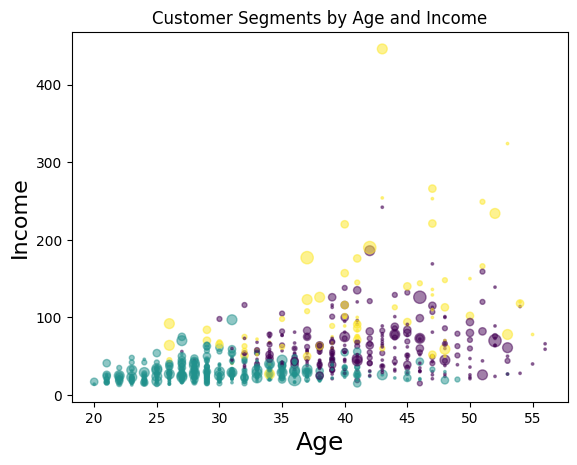

In [11]:
import matplotlib.pyplot as plt
import numpy as np

# Bubble area proportional to income (example: 2nd feature)
area = np.pi * (X[:, 1])**2

# Scatter plot: Age vs Income, colored by cluster
plt.scatter(X[:, 0], X[:, 3], s=area, c=labels.astype(float), alpha=0.5)

plt.xlabel('Age', fontsize=18)
plt.ylabel('Income', fontsize=16)
plt.title('Customer Segments by Age and Income')
plt.show()



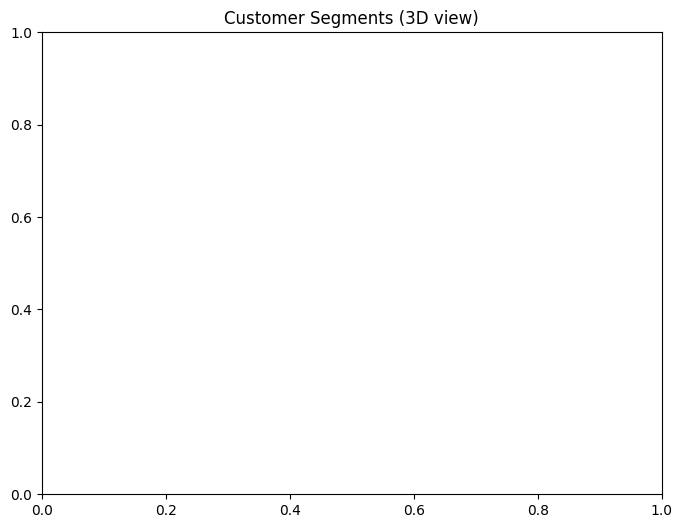

In [14]:
from mpl_toolkits.mplot3d import Axes3D
import matplotlib.pyplot as plt
import numpy as np

fig = plt.figure(1, figsize=(8, 6))
plt.clf()

ax = Axes3D(fig, rect=[0, 0, .95, 1], elev=48, azim=134)
plt.cla()

# Label axes
ax.set_xlabel('Education')
ax.set_ylabel('Age')
ax.set_zlabel('Income')

# 3D scatter, color by cluster labels
ax.scatter(X[:, 1], X[:, 0], X[:, 3], c=labels.astype(float))

plt.title("Customer Segments (3D view)")
plt.show()


k-means will partition your customers into mutually exclusive groups, for example, into 3 clusters. The customers in each cluster are similar to each other demographically.
Now we can create a profile for each group, considering the common characteristics of each cluster.
For example, the 3 clusters can be:

*   AFFLUENT, EDUCATED AND OLD AGED
*   MIDDLE AGED AND MIDDLE INCOME
*   YOUNG AND LOW INCOME


### Thank you for completing this lab!